# Splenic B cell vs. DP thymocyte comparison (mm9)

1. Aggregate contact maps of all MIA-Jet calls in each cell type
2. Venn diagram of overlapping calls, with aggregate contact maps of the DP-only / shared / Splenic-B-only calls

In [ ]:
import sys
sys.path.append('..')
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bioframe as bf
from matplotlib_venn import venn2

from utils.plotting import plot_n_hic, genomic_labels
from notebooks.func_iou import match_by_iou, unique_pairs
from notebooks.func_pileup import generate_bed_2, get_pileups_dynamic_resolution, remove_and_resize_square_stacks

In [ ]:
def safe_int(x):
    try:
        return int(x)
    except ValueError:
        return x

In [ ]:
# Pileup parameters
data_type = "oe"
expected_stack_size = 100

# Overlap parameters
iou_threshold = 0  # ANY overlap

exp_name_1 = "GSE199059_CD69negDPWTR1R2R3R4_merged"
exp_name_2 = "splenic-B-cell_WT_insitu-hic_Kieffer-Kwon-2018_GSE82144_mm9"

hic_file_1 = "/nfs/turbo/umms-minjilab/downloaded_data/GSE199059_CD69negDPWTR1R2R3R4_merged.hic" # mm9
hic_file_2 = "/nfs/turbo/umms-minjilab/downloaded_data/splenic-B-cell_WT_insitu-hic_Kieffer-Kwon-2018_GSE82144_mm9.hic" # mm9

data_name = "Splenic B-Cell vs. DP Thymocyte"

resolution = 50000 # 50Kb resolution
normalization = "VC_SQRT"

# Overlap parameter is relative to resolution
buffer_radius = 3 * resolution

# MIA-JET
output_name = "v2.0.3"
result_type = "q_val_0.15-0.15" # 50 bkb (OK)
resolution_miajet = resolution
f_pred_miajet_1_summary = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_1}_chr_combined_{genomic_labels(resolution_miajet)}/{exp_name_1}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_summary_table.csv"
f_pred_miajet_1_expanded = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_1}_chr_combined_{genomic_labels(resolution_miajet)}/{exp_name_1}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_expanded_table.csv"

f_pred_miajet_2_summary = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_2}_chr_combined_{genomic_labels(resolution_miajet)}/{exp_name_2}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_summary_table.csv"
f_pred_miajet_2_expanded = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/miajet/output_{output_name}/{exp_name_2}_chr_combined_{genomic_labels(resolution_miajet)}/{exp_name_2}_chr_combined_{result_type}_{genomic_labels(resolution_miajet)}_expanded_table.csv"


save_path = f"/nfs/turbo/umms-minjilab/sionkim/miajet_revision/analysis_{output_name}"


names = [
    "DP Thymocyte",
    "Splenic B-Cell",
    ]
names_abbrev = names

genomes = [
    "mm9",
    "mm9"
]

hic_file = [hic_file_1, hic_file_2]

miajet_table_list = [
    f_pred_miajet_1_summary,
    f_pred_miajet_2_summary,
]

miajet_position_list = [
    f_pred_miajet_1_expanded,
    f_pred_miajet_2_expanded,
]

In [ ]:
data_name += f" (MIA-Jet {result_type})"

# Summary (tables) and expanded (positions) MIA-Jet calls for each cell type
tables = [pd.read_csv(f, comment="#") for f in miajet_table_list]
positions = [pd.read_csv(f, comment="#") for f in miajet_position_list]

table_dict = dict(zip(names, tables))
position_dict = dict(zip(names, positions))

# Chromosomes with at least one call (used for the overlap computation)
common_chroms = set()
for t in tables:
    common_chroms.update(t["chrom"].unique())

bed_tables = [generate_bed_2(s, e, eps=500e3, fraction=1.5) for s, e in zip(tables, positions)]

chrom_sizes = bf.fetch_chromsizes(genomes[0], as_bed=True)

## Plot 1: Aggregate contact maps of all called

In [23]:
# PILEUPS OF ALL CALLED
agg_map = []
vmaxes = []
df_stack = []
for idx, bed_df in enumerate(bed_tables):
    # Get pileups for each bed_df
    s, d, r = get_pileups_dynamic_resolution(
        hic_file=hic_file[idx],
        bed_df_in=bed_df,
        expected_stack_size=expected_stack_size,
        chrom_sizes=chrom_sizes,
        chromosomes='all',
        window_range=(None, None),
        data_type=data_type,
        normalization=normalization,
        sort=True,
        verbose=True
    )
    # Remove centromeres and resize square stacks
    s, d = remove_and_resize_square_stacks(s, d, expected_stack_size)

    if data_type == "observed":
        s = np.log10(s + 1) # log transform for visualization

    a = np.mean(s, axis=0)
    vmaxes.append(np.percentile(a, 99))  # store the 99th percentile for color scaling
    agg_map.append(a)  # average over all stacks
    df_stack.append(d)  # used for the N in the titles

Retrieving pileups: 100%|██████████| 346/346 [00:13<00:00, 25.95it/s]


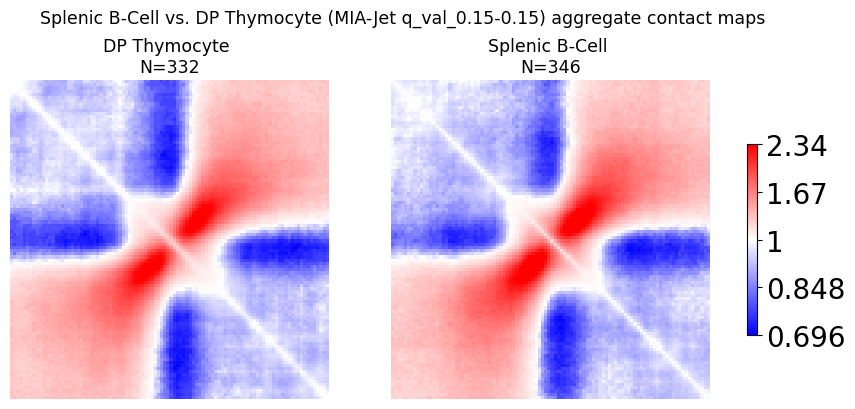

In [24]:
titles = [f"{names[i]} \nN={len(df_stack[i])}" for i in range(len(names))]

plot_n_hic(
    agg_map,
    suptitle=f"{data_name} aggregate contact maps",
    resolution=None,
    cmap_label=None,
    titles=titles,
    cmap='bwr',
    vcenter=1,
    standardize_cbar=True,
    show=True, 
    vmax=vmaxes,
    ppr=4,
    savepath=f"{save_path}/{data_name}_all_agg_map-{data_type}.png",
    cbar_fontsize=20,
    hide_axis=True,
)

## Plot 2: Overlap Venn diagram + aggregate contact maps of each subset

In [25]:
# COMPUTE OVERLAPS
results = pd.DataFrame(index=names, columns=names, dtype=int).fillna(0)
unique_identifiers = []
name_pairs = []
# fill main diagonal with the total number of jets from each method
for n in names:
    results.loc[n, n] = len(table_dict[n])

for n1, n2 in itertools.combinations(names, 2):

    print("-" * 20)
    print(f"Comparing {n1} and {n2}...")

    genome_wide_overlap = 0
    identifiers = []

    for chrom in common_chroms:

        # IOU method is per-chromosome so filter each table by chromosome
        t1 = position_dict[n1].loc[position_dict[n1]["chrom"] == chrom]
        t2 = position_dict[n2].loc[position_dict[n2]["chrom"] == chrom]

        if t1.empty or t2.empty:
            # if any of the two tables are empty then no need to check for overlaps.. there is none
            continue

        # Compute the pairs of jets in each direction
        pairs12 = match_by_iou(t1, t2, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")
        pairs21 = match_by_iou(t2, t1, buffer_radius=buffer_radius, iou_threshold=iou_threshold, x_label="x (bp)", y_label="y (bp)")

        # Construct graph and find unique pairs
        pairs = unique_pairs(pairs12, pairs21, method="optimal")

        genome_wide_overlap += len(pairs)
        identifiers += pairs # extend the list

    # Update reuslts table
    results.loc[n1, n2] = genome_wide_overlap
    results.loc[n2, n1] = genome_wide_overlap  # symmetric

    unique_identifiers.append(identifiers)
    name_pairs.append((n1, n2))

print("Genome-wide overlaps:")
print(results)

--------------------
Comparing DP Thymocyte and Splenic B-Cell...
Genome-wide overlaps:
                DP Thymocyte  Splenic B-Cell
DP Thymocyte           332.0           135.0
Splenic B-Cell         135.0           346.0


In [28]:
# COLLECT AGG DATA FOR EACH OVERLAP SUBSET (A only, A & B, B only)
safe_convert = np.vectorize(safe_int)
agg_map_pairs = [] # aggregate contact map data
for (n1, n2), pairs in zip(name_pairs, unique_identifiers):

    if len(pairs) == 0:
        uid1 = np.array([])
        uid2 = np.array([])
    else:
        uid1 = safe_convert(np.array(pairs)[:, 0])  # unique identifiers from n1
        uid2 = safe_convert(np.array(pairs)[:, 1])  # unique identifiers from n2

    A_idx = names.index(n1)
    B_idx = names.index(n2)

    # Summary dataframes
    df_A = table_dict[n1]
    df_B = table_dict[n2]
    # Expanded dataframes
    df_pos_A = position_dict[n1]
    df_pos_B = position_dict[n2]

    df_intersection = df_A[df_A["unique_id"].isin(uid1)].reset_index(drop=True)
    df_diff_A = df_A[~df_A["unique_id"].isin(uid1)].reset_index(drop=True)
    df_diff_B = df_B[~df_B["unique_id"].isin(uid2)].reset_index(drop=True)

    df_pos_intersection = df_pos_A[df_pos_A["unique_id"].isin(uid1)].reset_index(drop=True)
    df_pos_diff_A = df_pos_A[~df_pos_A["unique_id"].isin(uid1)].reset_index(drop=True)
    df_pos_diff_B = df_pos_B[~df_pos_B["unique_id"].isin(uid2)].reset_index(drop=True)

    # Make bed files to get stacks
    bed_intersection = generate_bed_2(df_intersection, df_pos_intersection, eps=500e3, fraction=1.5)
    bed_diff_A = generate_bed_2(df_diff_A, df_pos_diff_A, eps=500e3, fraction=1.5)
    bed_diff_B = generate_bed_2(df_diff_B, df_pos_diff_B, eps=500e3, fraction=1.5)

    bed_frames = [bed_diff_A, bed_intersection, bed_diff_B]
    chrom_sizes_comparison = [bf.fetch_chromsizes(genomes[A_idx]), bf.fetch_chromsizes(genomes[A_idx]), bf.fetch_chromsizes(genomes[B_idx])]
    hic_file_comparison = [hic_file[A_idx], hic_file[A_idx], hic_file[B_idx]]

    agg_map = []
    for j, bed_df in enumerate(bed_frames):
        # Get pileups for each bed_df
        s, d, r = get_pileups_dynamic_resolution(
            hic_file=hic_file_comparison[j],
            bed_df_in=bed_df,
            expected_stack_size=expected_stack_size,
            chrom_sizes=chrom_sizes_comparison[j],
            chromosomes='all',
            window_range=(None, None),
            data_type=data_type,
            normalization=normalization,
            sort=True,
            verbose=True
        )

        # Remove centromeres and resize square stacks
        s, d = remove_and_resize_square_stacks(s, d, expected_stack_size)

        if data_type == "observed":
            s = np.log10(s + 1) # log transform for visualization

        agg_map.append(np.mean(s, axis=0))  # average over all stacks

    agg_map_pairs.append(agg_map)

agg_map_pairs = np.array(agg_map_pairs)

Retrieving pileups: 100%|██████████| 211/211 [00:06<00:00, 31.51it/s]


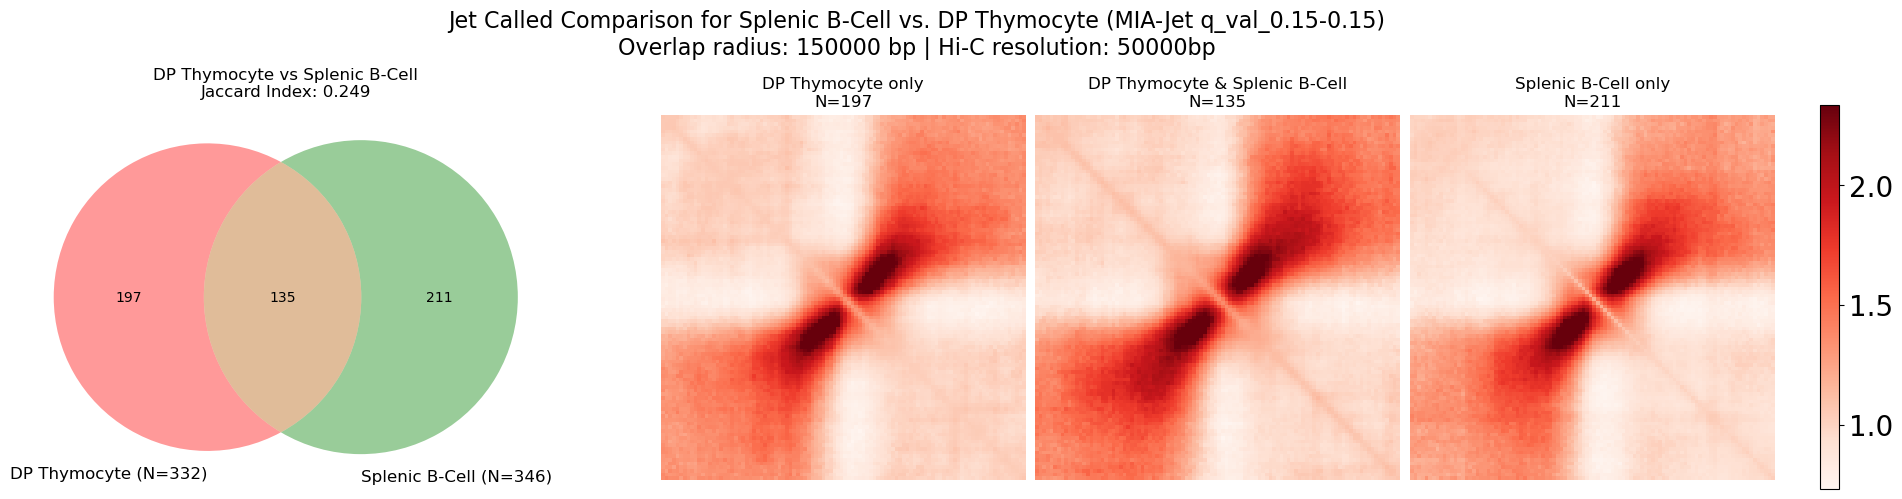

In [30]:
# PLOT VENN DIAGRAM
pairs = list(itertools.combinations(names, 2))
num_pairs = len(pairs)

fig, axes = plt.subplots(num_pairs, 4, figsize=(5*4, 5*num_pairs), layout='constrained', width_ratios=[2, 1, 1, 1])

for row, (A, B) in enumerate(pairs):
    # compute overlaps as before
    total_A = results.loc[A, A]
    total_B = results.loc[B, B]
    inter = results.loc[A, B]
    only_A = total_A - inter
    only_B = total_B - inter

    # column 0: the Venn
    ax = axes[row]
    venn2(subsets=(int(only_A), int(only_B), int(inter)),
        set_labels=(f"{A} (N={int(total_A)})", f"{B} (N={int(total_B)})"),
        ax=ax)
    ax.set_title(f"{A} vs {B}\nJaccard Index: {inter / (inter + only_A + only_B):.3f}")

    # columns 1–3: the three imshows
    # agg_map_pairs.shape == (n_pairs, 3, H, W)
    A_idx = names.index(A)
    B_idx = names.index(B)
    A_abbrev = names_abbrev[A_idx]
    B_abbrev = names_abbrev[B_idx]
    titles = [f"{A_abbrev} only", f"{A_abbrev} & {B_abbrev}", f"{B_abbrev} only"]
    counts = [int(only_A), int(inter), int(only_B)]
    row_imgs = agg_map_pairs[row]
    row_vmax = max(np.percentile(img, 99) for img in row_imgs)
    for col_idx in range(3):
        ax = axes[col_idx+1]
        img = agg_map_pairs[row, col_idx]
        im = ax.imshow(img, cmap="Reds", interpolation="none", vmax=np.percentile(img, 99))
        ax.set_title(f"{titles[col_idx]}\nN={counts[col_idx]}")
        ax.axis('off')
    cba = fig.colorbar(im, ax=axes[1:], fraction=0.02, pad=0.04)
    cba.ax.tick_params(labelsize=20)


fig.suptitle(f"Jet Called Comparison for {data_name}\nOverlap radius: {int(buffer_radius)} bp | Hi-C resolution: {resolution}bp", fontsize=16)

plt.savefig(f"{save_path}/{data_name}_venn_diagram-agg.png", dpi=300)

plt.show()
